# 8r_census_migration: net migration rate by 5-year age band from the census, 2011 Tohoku and 2016 Kumamoto

The census (国勢調査) asks everyone where they lived **five years earlier** (5年前の常住地). For each municipality this gives, by sex and 5-year age band:

- **in-migrants**: residents on census day who lived in another municipality or abroad five years earlier;
- **out-migrants**: people who lived in the municipality five years earlier and now live in another municipality in Japan.

So the census measures net migration **directly, by where people actually live**, not by where they are registered as in 住民基本台帳 (3r–7r). This matters most for the Fukushima evacuation, where many evacuees kept their registration.

**Census periods** (1 October to 1 October):

| Census | Period | Tohoku (quake 2011-03-11) | Kumamoto (quake 2016-04-14) |
|---|---|---|---|
| 2010 | 2005–10 | before | before |
| 2015 | 2010–15 | **quake period** (5 months before, 4½ years after) | before |
| 2020 | 2015–20 | after | **quake period** (6½ months before, 4½ years after; ends with the first COVID-19 months) |

The 2000 census also asked the question but is not used. 2005 did not ask it, and the 2025 migration tables are not published yet (November 2026).

**Data:** `dt/census_idou_age_sex_5yr_long.qs2`, built by `src/build_census_idou.R` (e-Stat API; `doc/data.md` §8). Total population including foreign residents, both sexes.

**Municipalities and groups:** as in 4r. Tohoku: the 123 listed under 東日本 and 福島 in `1_市町村一覧`; Kumamoto: the 45 listed under 熊本.

**Rate** for an age band (age on census day, i.e. at the **end** of the period):

> net migration rate = 1000 × (in − out) ÷ (5 × P<sub>5</sub>) per 1,000 per year,
>
> P<sub>5</sub> = people who lived in the municipality five years earlier and are alive and in Japan on census day (stayers + moves within the municipality + out-migrants).

- Ages 0–4 are left out: they were not born five years earlier.
- Out-migration abroad is not observed. In-migration from abroad is counted.
- Groups are pooled: in, out and P<sub>5</sub> are summed before dividing.
- Deaths do not enter: the census counts survivors only. Tsunami victims are therefore neither in- nor out-migrants here (unlike a residual estimate).

**Unknown migration status (不詳).** 2.4% (2010), 3.7% (2015) and 5.8% (2020) of residents in the study municipalities.
- 2015 and 2020 use the official **不詳補完結果** (imputed) tables.
- 2010 has no imputed table. Unknowns are allocated proportionally (section 1), and the same correction applied to 2015/2020 is checked against the imputed tables.

Figures are written to `res/` as `8r_<NN>_<item>.png` via `show_save()`; tables are shown here only.

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png", dplyr.summarise.inform = FALSE)

root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"

nb_prefix <- "8r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Source: 国勢調査 (Population Census) 2010, 2015, 2020, 移動人口の男女・年齢等集計 (5年前の常住地). ",
                   "Total population incl. foreign residents. 2015/2020: 不詳補完結果 (imputed); ",
                   "2010: unknown migration status allocated proportionally.")

# Census periods, labelled by their years; the period that contains each quake
periods <- c("2010" = "2005–10", "2015" = "2010–15", "2020" = "2015–20")
events <- list(
  tohoku   = list(title = "2011 Great East Japan Earthquake", quake = "2010–15", base = "2005–10",
                  cols = c("2005–10" = "#8a8a85", "2010–15" = "#eb6834", "2015–20" = "#2a78d6")),
  kumamoto = list(title = "2016 Kumamoto Earthquake", quake = "2015–20", base = c("2005–10", "2010–15"),
                  cols = c("2005–10" = "#b5b4ae", "2010–15" = "#5c5c58", "2015–20" = "#eb6834"))
)
bands <- c(paste0(seq(5, 80, 5), "_", seq(9, 84, 5)), "85+")
band_lab <- setNames(sub("_", "–", bands), bands)

In [2]:
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 %in% c("東日本", "福島", "熊本")) |>
  transmute(event = ifelse(災害 == "熊本", "kumamoto", "tohoku"),
            code = 市町村コード, muni = 市町村, pref = 県, short = sub("^.*郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`),
            evacuation = 避難指示あり %in% c("TRUE", "True", "1")) |>
  mutate(group = case_when(
    event == "tohoku" & pref == "福島県" & evacuation ~ "福島 避難指示 (evacuation order)",
    event == "tohoku" & pref != "福島県" & zenkai_rate >= 1 ~ "岩手・宮城 全壊率 ≥ 1",
    event == "tohoku" ~ "Other listed (Tohoku)",
    zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)",
    code == "43100" ~ "熊本市",
    TRUE ~ "Other listed (Kumamoto)"))
group_levels <- list(
  tohoku = c("岩手・宮城 全壊率 ≥ 1", "福島 避難指示 (evacuation order)", "Other listed (Tohoku)"),
  kumamoto = c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed (Kumamoto)"))
study |> count(event, group) |> as.data.frame()

event,group,n
<chr>,<chr>,<int>
kumamoto,High damage (全壊率 ≥ 1),5
kumamoto,Other listed (Kumamoto),39
kumamoto,熊本市,1
tohoku,Other listed (Tohoku),91
tohoku,岩手・宮城 全壊率 ≥ 1,22
tohoku,福島 避難指示 (evacuation order),10


In [3]:
cen <- qs_read(file.path(root, "dt/census_idou_age_sex_5yr_long.qs2")) |> filter(sex == "計")
wide <- cen |>
  pivot_wider(names_from = measure, values_from = n, values_fill = 0) |>
  mutate(unk = unk_status + unk_origin,
         f = ifelse(resident > unk, resident / (resident - unk), 1))
# National correction factor by age: out-migrants with unknown status are counted at
# their (spread-out) destinations, so the outflow is scaled by the national unknown share.
f_nat <- wide |> filter(level == "national") |> select(census_year, version, age_band, f_nat = f)

# in, out and P5 for one table; correct = allocate unknown status proportionally
flows <- function(d, correct) {
  d |>
    left_join(f_nat, by = c("census_year", "version", "age_band")) |>
    mutate(f_here = if (correct) f else 1, f_out = if (correct) f_nat else 1,
           inn = (in_pref + in_other + in_abroad) * f_here,
           out = (out_pref + out_other) * f_out,
           p5 = (stay + within) * f_here + out,
           net = inn - out) |>
    select(census_year, version, level, code, name, age_band, resident, unk, inn, out, p5, net)
}
used <- bind_rows(
  flows(wide |> filter(census_year == 2010, version == "raw"), TRUE),
  flows(wide |> filter(census_year %in% c(2015, 2020), version == "imputed"), FALSE)) |>
  mutate(period = factor(periods[as.character(census_year)], levels = periods))

mr <- used |>
  filter(code %in% study$code, age_band %in% bands) |>
  inner_join(study |> select(code, event, group, short, pref, zenkai_rate, evacuation), by = "code") |>
  mutate(age_band = factor(age_band, levels = bands))

# Coverage: every study municipality in every census
mr |> group_by(event, period) |>
  summarise(municipalities = n_distinct(code), residents_5plus = round(sum(inn + p5 - out)),
            in_ = round(sum(inn)), out = round(sum(out)), .groups = "drop") |> as.data.frame()

# Municipalities with no residents on a census day (Fukushima evacuation zones)
wide |> filter(code %in% study$code, age_band == "total", version != "raw" | census_year == 2010) |>
  group_by(code) |> filter(any(resident == 0)) |> ungroup() |>
  select(census_year, code, name, resident) |>
  pivot_wider(names_from = census_year, values_from = resident, names_prefix = "residents_") |> as.data.frame()

event,period,municipalities,residents_5plus,in_,out
<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>
kumamoto,2005–10,45,1727086,188569,202495
kumamoto,2010–15,45,1708705,184698,192645
kumamoto,2015–20,45,1668951,181349,190223
tohoku,2005–10,123,4431407,401627,464260
tohoku,2010–15,123,4285679,475572,549220
tohoku,2015–20,123,4108028,401092,455414


code,name,residents_2010,residents_2015,residents_2020
<chr>,<chr>,<dbl>,<dbl>,<dbl>
07543,富岡町,16001,0,2128
07545,大熊町,11515,0,847
07546,双葉町,6932,0,0


## 1. Unknown migration status, and the 2010 correction

Census-day residents whose migration status is unknown (移動状況「不詳」, or moved from an unknown municipality) cannot be split into stayers and in-migrants. People who left a municipality and have unknown status at their new address are missing from its out-migrants.

**Proportional allocation** (used for 2010):
- in-migrants, stayers and moves within the municipality are scaled by *f* = residents ÷ (residents − unknown) of the municipality and age band;
- out-migrants are scaled by the **national** *f* of the age band, because they are counted at destinations spread across Japan.

**Check:** the same correction applied to the raw 2015 and 2020 tables, compared with the official imputed tables (不詳補完結果), study municipalities, per 1,000 per year. Bias and RMSE are weighted by P<sub>5</sub>.

In [4]:
check <- bind_rows(
  flows(wide |> filter(census_year %in% c(2015, 2020), version == "raw"), FALSE) |> mutate(kind = "raw, uncorrected"),
  flows(wide |> filter(census_year %in% c(2015, 2020), version == "raw"), TRUE) |> mutate(kind = "raw, proportional")) |>
  filter(code %in% study$code, age_band %in% bands) |>
  inner_join(used |> select(census_year, code, age_band, net_i = net, p5_i = p5), by = c("census_year", "code", "age_band")) |>
  filter(p5 > 0, p5_i > 0) |>
  mutate(rate = 1000 * net / (5 * p5), rate_i = 1000 * net_i / (5 * p5_i))
check |> group_by(kind, census_year) |>
  summarise(bias = weighted.mean(rate - rate_i, p5_i), rmse = sqrt(weighted.mean((rate - rate_i)^2, p5_i)),
            median_abs = median(abs(rate - rate_i)), .groups = "drop") |>
  mutate(across(where(is.double) & !census_year, ~ round(.x, 2))) |> as.data.frame()
# By age band (proportional correction): where the 2010 rates are least reliable
check |> filter(kind == "raw, proportional") |>
  group_by(census_year, age = band_lab[age_band]) |>
  summarise(bias = round(weighted.mean(rate - rate_i, p5_i), 1), .groups = "drop") |>
  pivot_wider(names_from = census_year, values_from = bias, names_prefix = "bias_") |>
  arrange(match(age, band_lab)) |> as.data.frame()

kind,census_year,bias,rmse,median_abs
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
"raw, proportional",2015,0.16,2.25,0.48
"raw, proportional",2020,0.03,2.21,0.60
"raw, uncorrected",2015,1.52,3.81,0.57
"raw, uncorrected",2020,1.49,4.04,0.99


age,bias_2015,bias_2020
<chr>,<dbl>,<dbl>
5–9,-0.9,-1.0
10–14,-0.3,-0.4
15–19,3.5,0.7
20–24,6.8,6.2
25–29,-0.1,-0.6
30–34,-2.1,-1.7
35–39,-1.3,-1.1
40–44,-0.7,-0.6
45–49,-0.4,-0.3


The correction removes most of the bias of the uncorrected tables. The remaining error is concentrated at **ages 15–24**, where the corrected rate is too high by about 3–7 per 1,000 per year: unknown status is more common among young movers than among stayers. Read the 2010 (2005–10) rates at 15–24 with this in mind. They are biased upwards, i.e. the true pre-quake out-migration of young adults was slightly stronger.

## 2. Age profiles

Figures 1–2: net migration rate by age band for each census period, pooled over each group. Ages are on census day (the end of the period). A person aged 20–24 in 2015 was 15–19 in 2010.

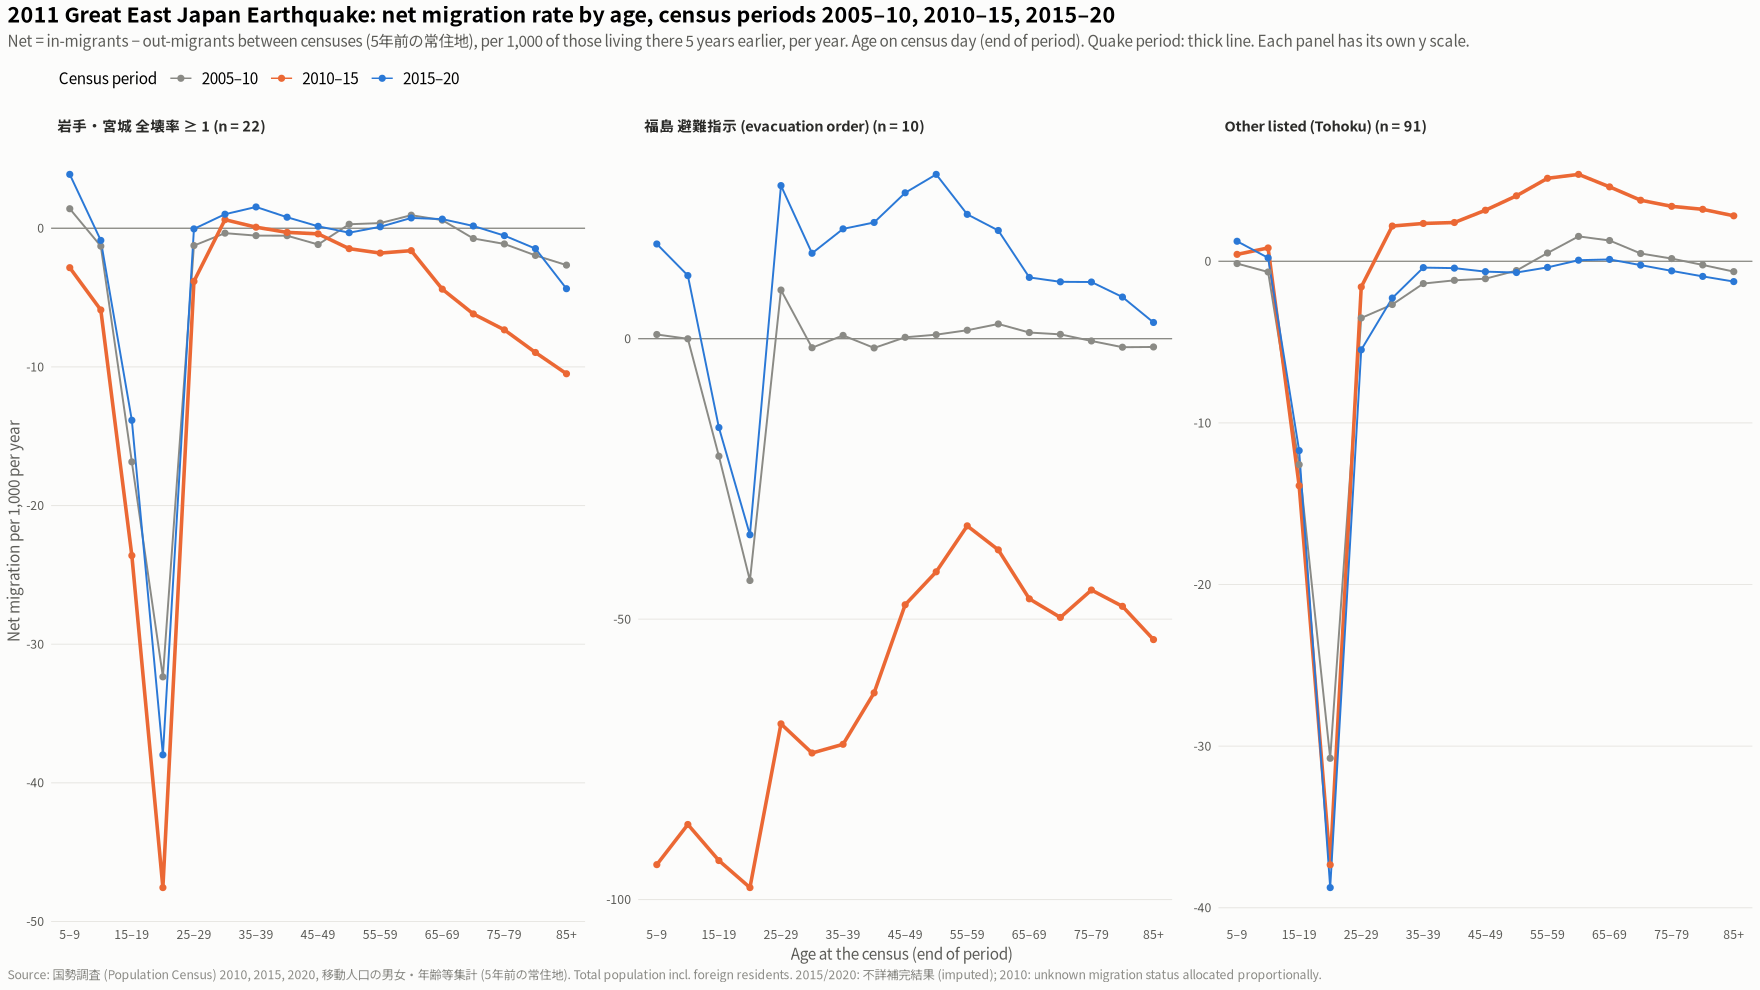

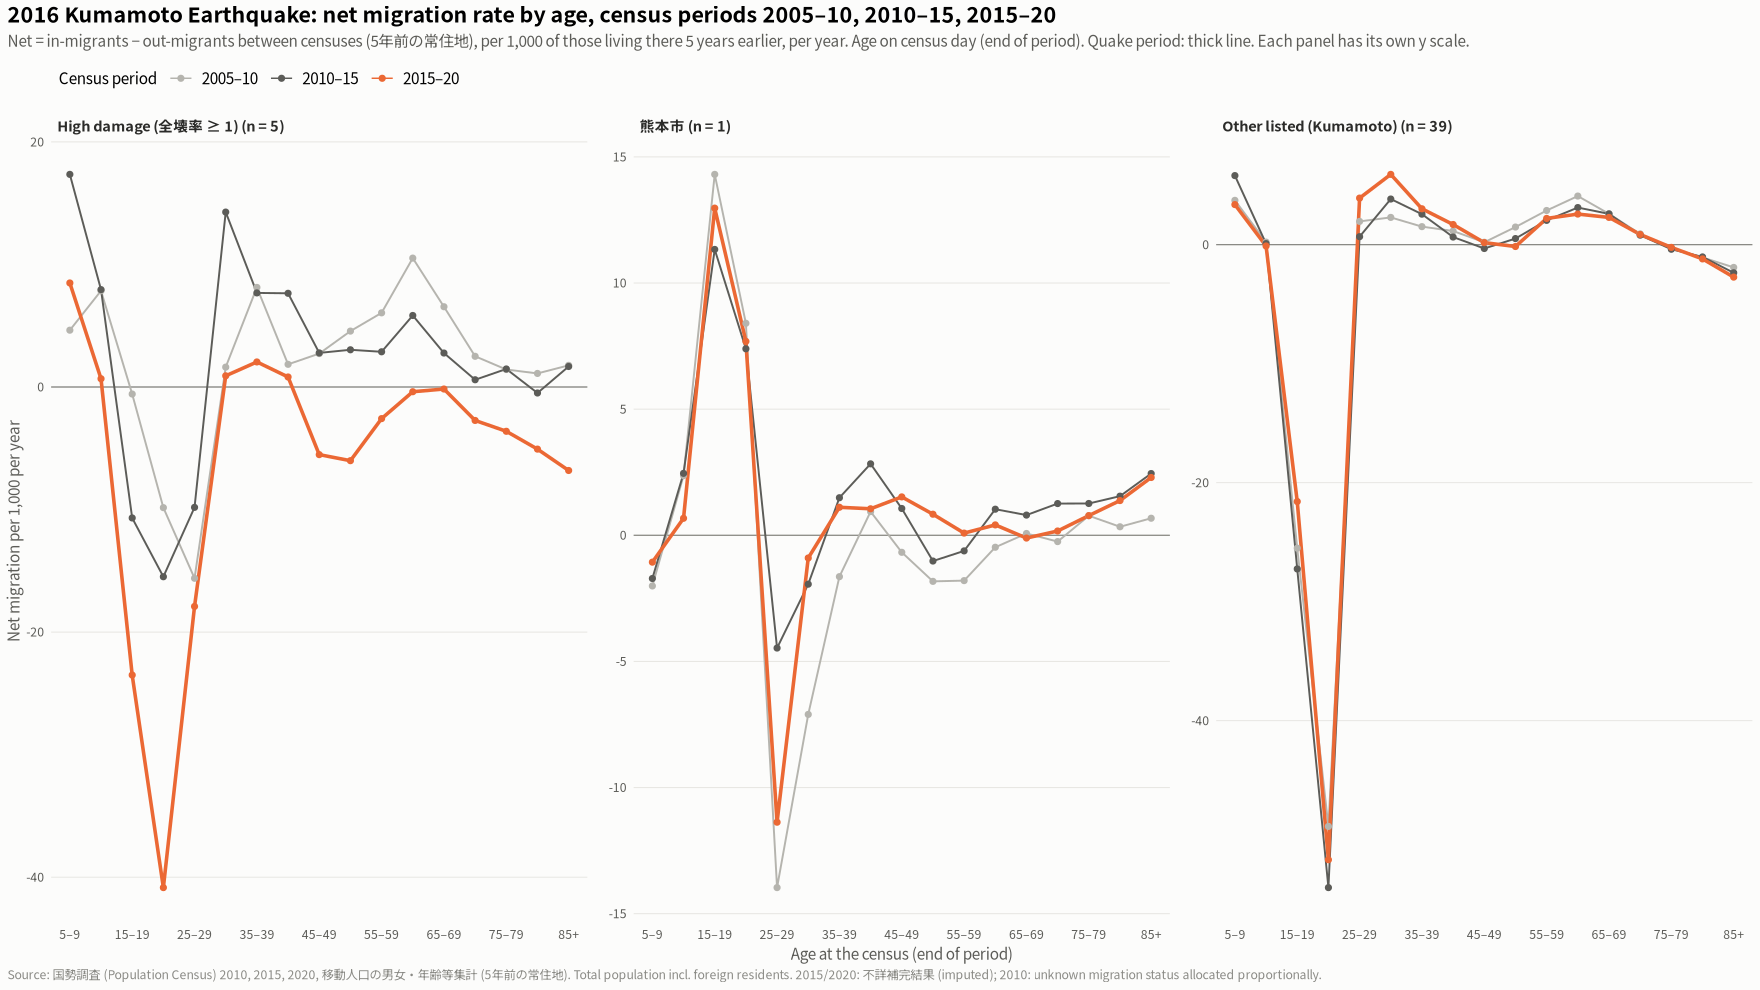

In [5]:
pool <- function(d, ...) d |> group_by(...) |>
  summarise(net = sum(net), p5 = sum(p5), .groups = "drop") |>
  mutate(rate = 1000 * net / (5 * p5))
prof <- pool(mr, event, group, period, age_band)

plot_profile <- function(e, free = TRUE) {
  ev <- events[[e]]
  d <- prof |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  n_by <- study |> filter(event == e) |> count(group) |> mutate(group = factor(group, levels = group_levels[[e]]))
  ggplot(d, aes(age_band, rate, colour = period, group = period)) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(aes(linewidth = period == ev$quake)) +
    geom_point(size = 1.6) +
    facet_wrap(~group, nrow = 1, scales = if (free) "free_y" else "fixed",
               labeller = as_labeller(setNames(sprintf("%s (n = %d)", n_by$group, n_by$n), n_by$group))) +
    scale_colour_manual(values = ev$cols, name = "Census period") +
    scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
    scale_x_discrete(labels = function(l) ifelse(seq_along(l) %% 2 == 1, band_lab[l], "")) +
    labs(title = sprintf("%s: net migration rate by age, census periods 2005–10, 2010–15, 2015–20", ev$title),
         subtitle = paste0("Net = in-migrants − out-migrants between censuses (5年前の常住地), per 1,000 of those living there 5 years earlier, per year. ",
                           "Age on census day (end of period). Quake period: thick line.",
                           if (free) " Each panel has its own y scale." else ""),
         x = "Age at the census (end of period)", y = "Net migration per 1,000 per year", caption = src_note) +
    base_theme()
}
show_save(plot_profile("tohoku"), "01_profile_tohoku", height = 6.5)
show_save(plot_profile("kumamoto"), "02_profile_kumamoto", height = 6.5)

In [6]:
# Broad age groups (age at the census), per 1,000 per year
broad <- mr |>
  mutate(ages = case_when(age_band %in% c("5_9", "10_14") ~ "5–14",
                          age_band %in% c("15_19") ~ "15–19",
                          age_band %in% c("20_24", "25_29", "30_34", "35_39") ~ "20–39",
                          age_band %in% c("40_44", "45_49", "50_54", "55_59", "60_64") ~ "40–64",
                          TRUE ~ "65+"),
         ages = factor(ages, levels = c("5–14", "15–19", "20–39", "40–64", "65+")))
pool(broad, event, group, period, ages) |>
  mutate(group = factor(group, levels = unlist(group_levels)), rate = round(rate, 1)) |>
  select(event, group, period, ages, rate) |>
  pivot_wider(names_from = ages, values_from = rate) |>
  arrange(event, group, period) |> as.data.frame()

event,group,period,5–14,15–19,20–39,40–64,65+
<chr>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
kumamoto,High damage (全壊率 ≥ 1),2005–10,6.3,-0.6,-3.7,5.6,2.8
kumamoto,High damage (全壊率 ≥ 1),2010–15,12.7,-10.7,-0.1,4.5,1.4
kumamoto,High damage (全壊率 ≥ 1),2015–20,4.5,-23.5,-12.4,-2.6,-3.4
kumamoto,熊本市,2005–10,0.2,14.3,-4.0,-0.8,0.3
kumamoto,熊本市,2010–15,0.4,11.3,0.4,0.7,1.4
kumamoto,熊本市,2015–20,-0.2,13.0,-0.9,0.8,0.8
kumamoto,Other listed (Kumamoto),2005–10,1.9,-25.5,-10.6,2.1,0.2
kumamoto,Other listed (Kumamoto),2010–15,2.9,-27.2,-11.2,1.4,0.1
kumamoto,Other listed (Kumamoto),2015–20,1.6,-21.6,-9.7,1.4,-0.1


## 3. Change from the pre-quake period

Figures 3–4: the quake-period (and, for Tohoku, the following) rate minus the pre-quake rate, by age band, in points per 1,000 per year.

- **Tohoku:** baseline 2005–10 (the only pre-quake census period available here).
- **Kumamoto:** baseline = mean of the 2005–10 and 2010–15 rates. The grey line, 2010–15 minus 2005–10, is a **placebo**: the change between two pre-quake periods, i.e. how much the rate drifts without a quake.

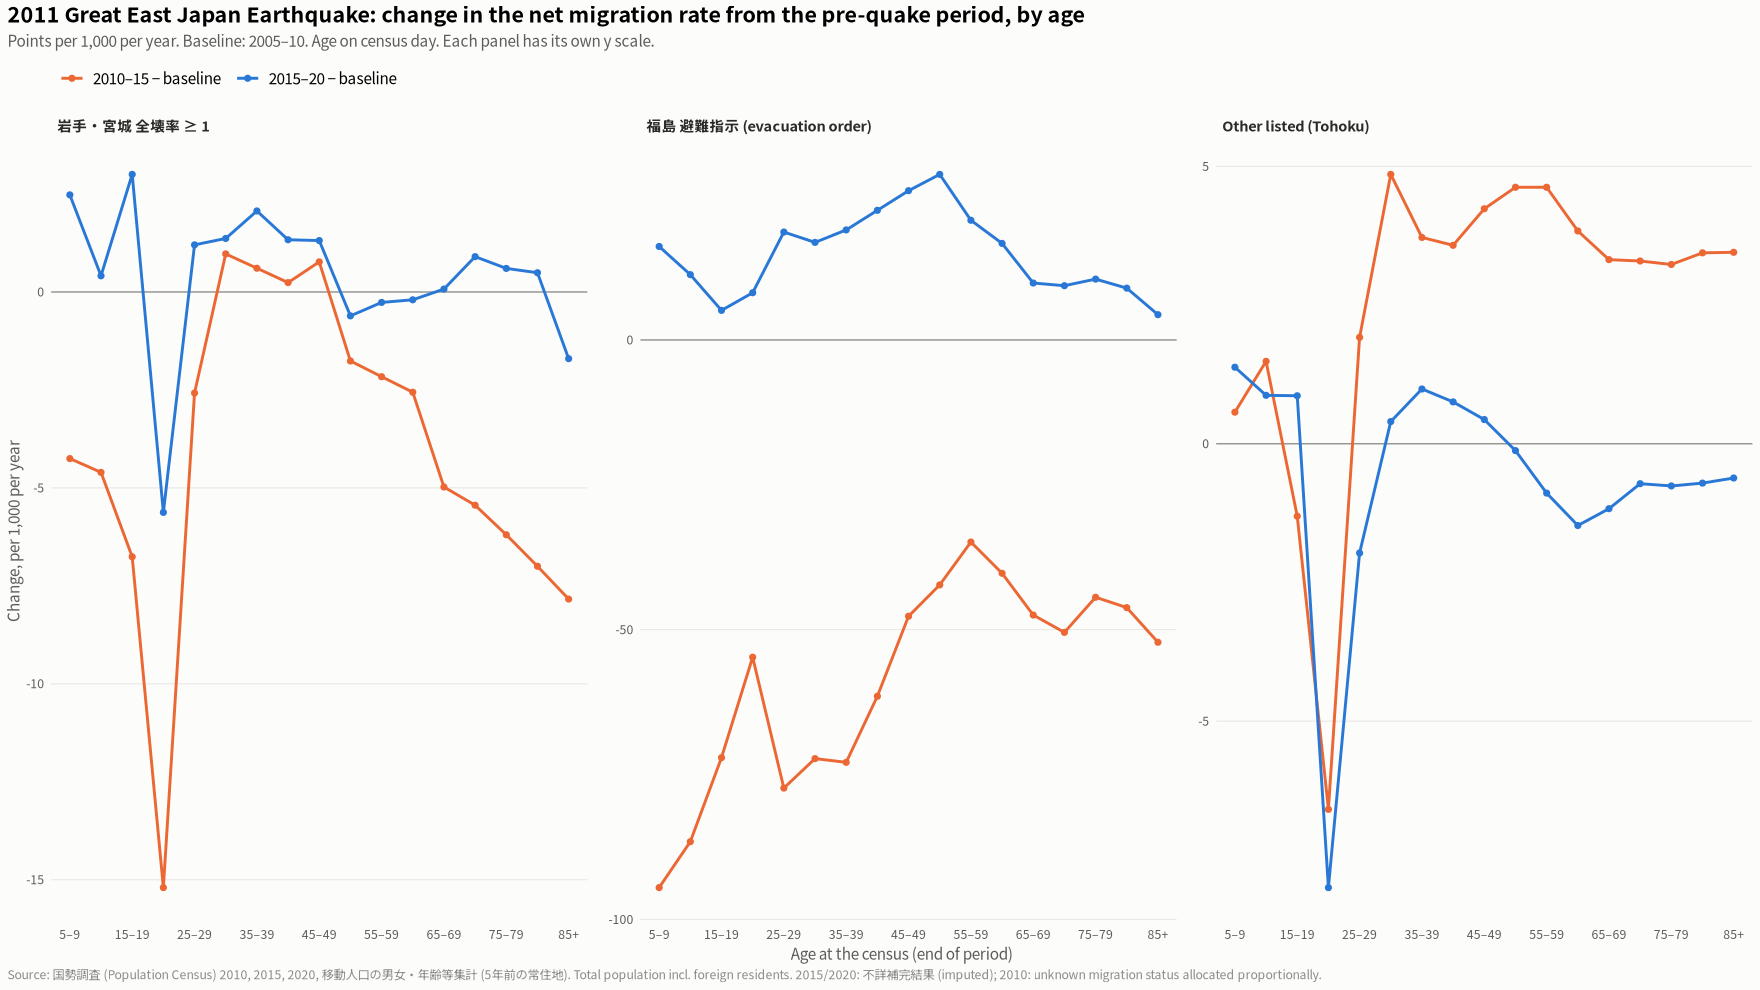

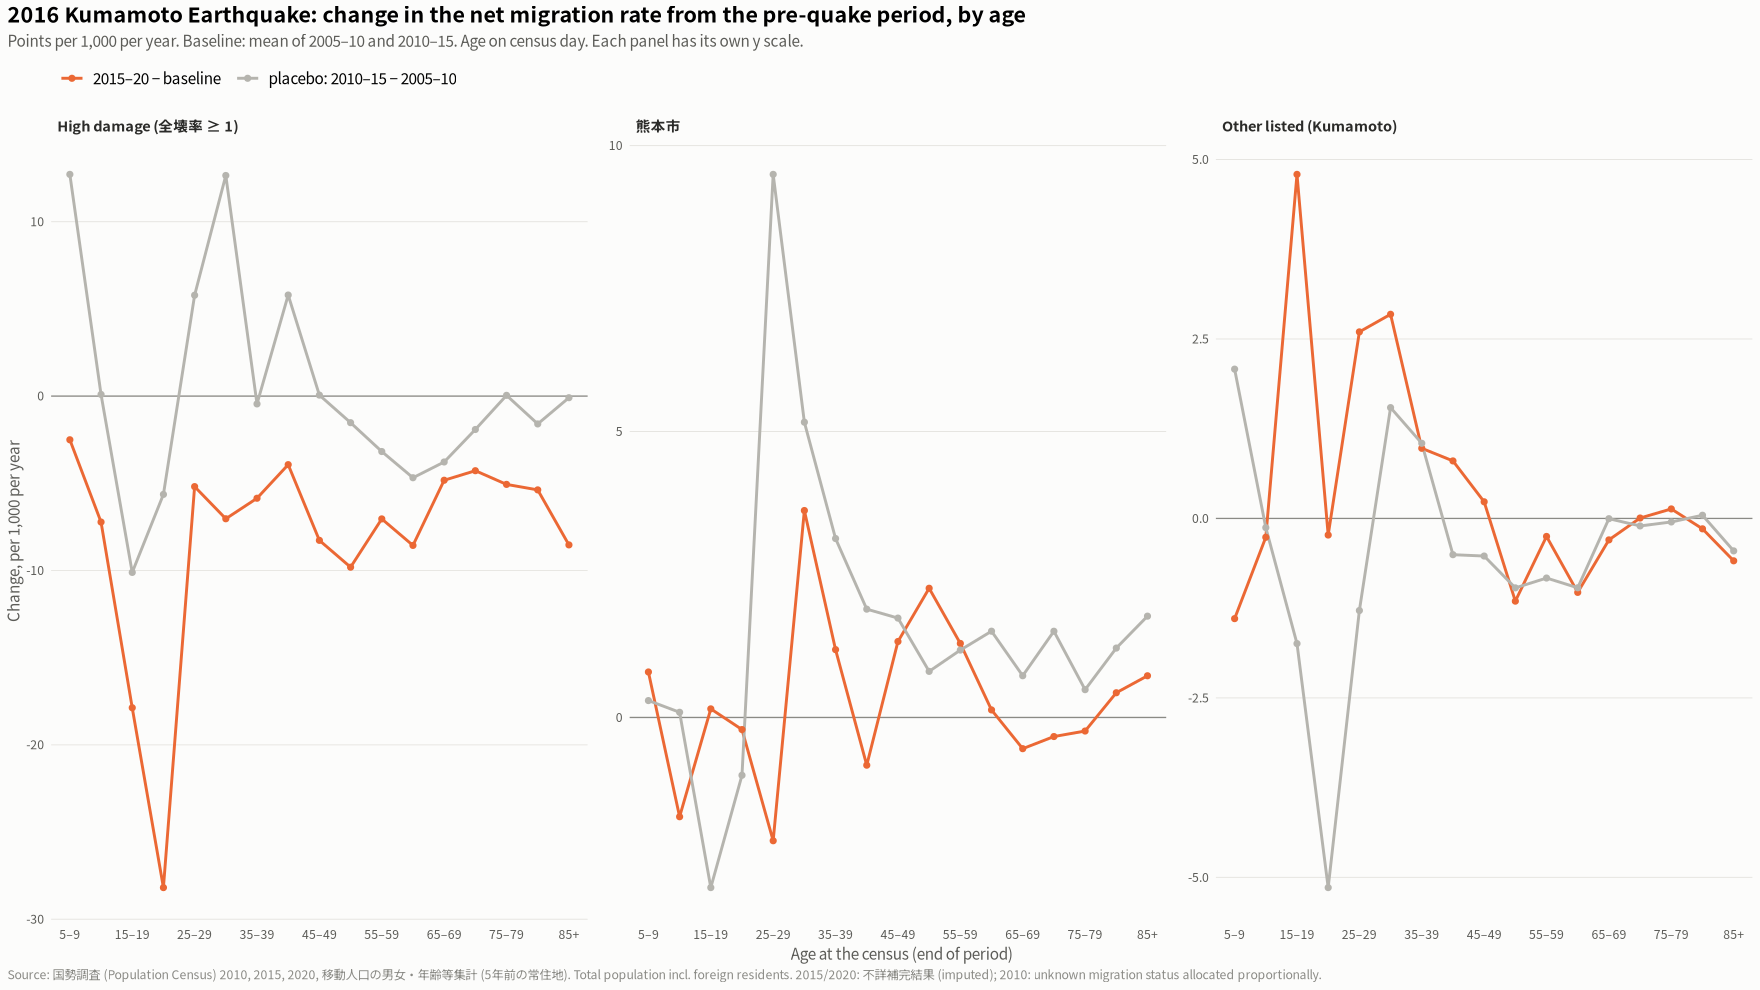

In [7]:
chg <- bind_rows(lapply(names(events), function(e) {
  ev <- events[[e]]
  p <- prof |> filter(event == e)
  base <- p |> filter(period %in% ev$base) |> group_by(group, age_band) |> summarise(base = mean(rate), .groups = "drop")
  out <- p |> filter(!period %in% ev$base) |> inner_join(base, by = c("group", "age_band")) |>
    mutate(change = rate - base, what = paste(period, "− baseline"))
  if (length(ev$base) == 2) {
    plc <- p |> filter(period %in% ev$base) |> select(group, age_band, period, rate) |>
      pivot_wider(names_from = period, values_from = rate) |>
      mutate(change = .data[[ev$base[2]]] - .data[[ev$base[1]]], what = sprintf("placebo: %s − %s", ev$base[2], ev$base[1]))
    out <- bind_rows(out, plc)
  }
  out |> mutate(event = e)
}))

plot_change <- function(e) {
  ev <- events[[e]]
  d <- chg |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  whats <- unique(d$what)
  cols <- setNames(ifelse(grepl("placebo", whats), "#b5b4ae",
                          ifelse(grepl(ev$quake, whats, fixed = TRUE), "#eb6834", "#2a78d6")), whats)
  ggplot(d, aes(age_band, change, colour = what, group = what)) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(linewidth = 0.9) + geom_point(size = 1.6) +
    facet_wrap(~group, nrow = 1, scales = "free_y") +
    scale_colour_manual(values = cols, name = NULL) +
    scale_x_discrete(labels = function(l) ifelse(seq_along(l) %% 2 == 1, band_lab[l], "")) +
    labs(title = sprintf("%s: change in the net migration rate from the pre-quake period, by age", ev$title),
         subtitle = sprintf("Points per 1,000 per year. Baseline: %s. Age on census day. Each panel has its own y scale.",
                            if (length(ev$base) == 1) ev$base else paste0("mean of ", paste(ev$base, collapse = " and "))),
         x = "Age at the census (end of period)", y = "Change, per 1,000 per year", caption = src_note) +
    base_theme()
}
show_save(plot_change("tohoku"), "03_change_tohoku", height = 6.5)
show_save(plot_change("kumamoto"), "04_change_kumamoto", height = 6.5)

## 4. By municipality

Figures 5–6: net migration rate of every municipality by age band and census period. Rows are ordered by group, then by 全壊率. Colours are capped at ±50 per 1,000 per year.

- In small municipalities a band can have only a few dozen people, so single cells are noisy; read patterns across rows.
- Grey cells: nobody lived there at the start of the period (Fukushima towns that were still fully evacuated on the 2015 census day).
- The Fukushima towns that were fully evacuated in 2015 show −200, i.e. everyone who lived there in 2010 had left.
- In 2015–20, towns where people had started to return (楢葉町, 広野町, 川内村 …) show large positive rates: the returnees are divided by the few residents of 2015.

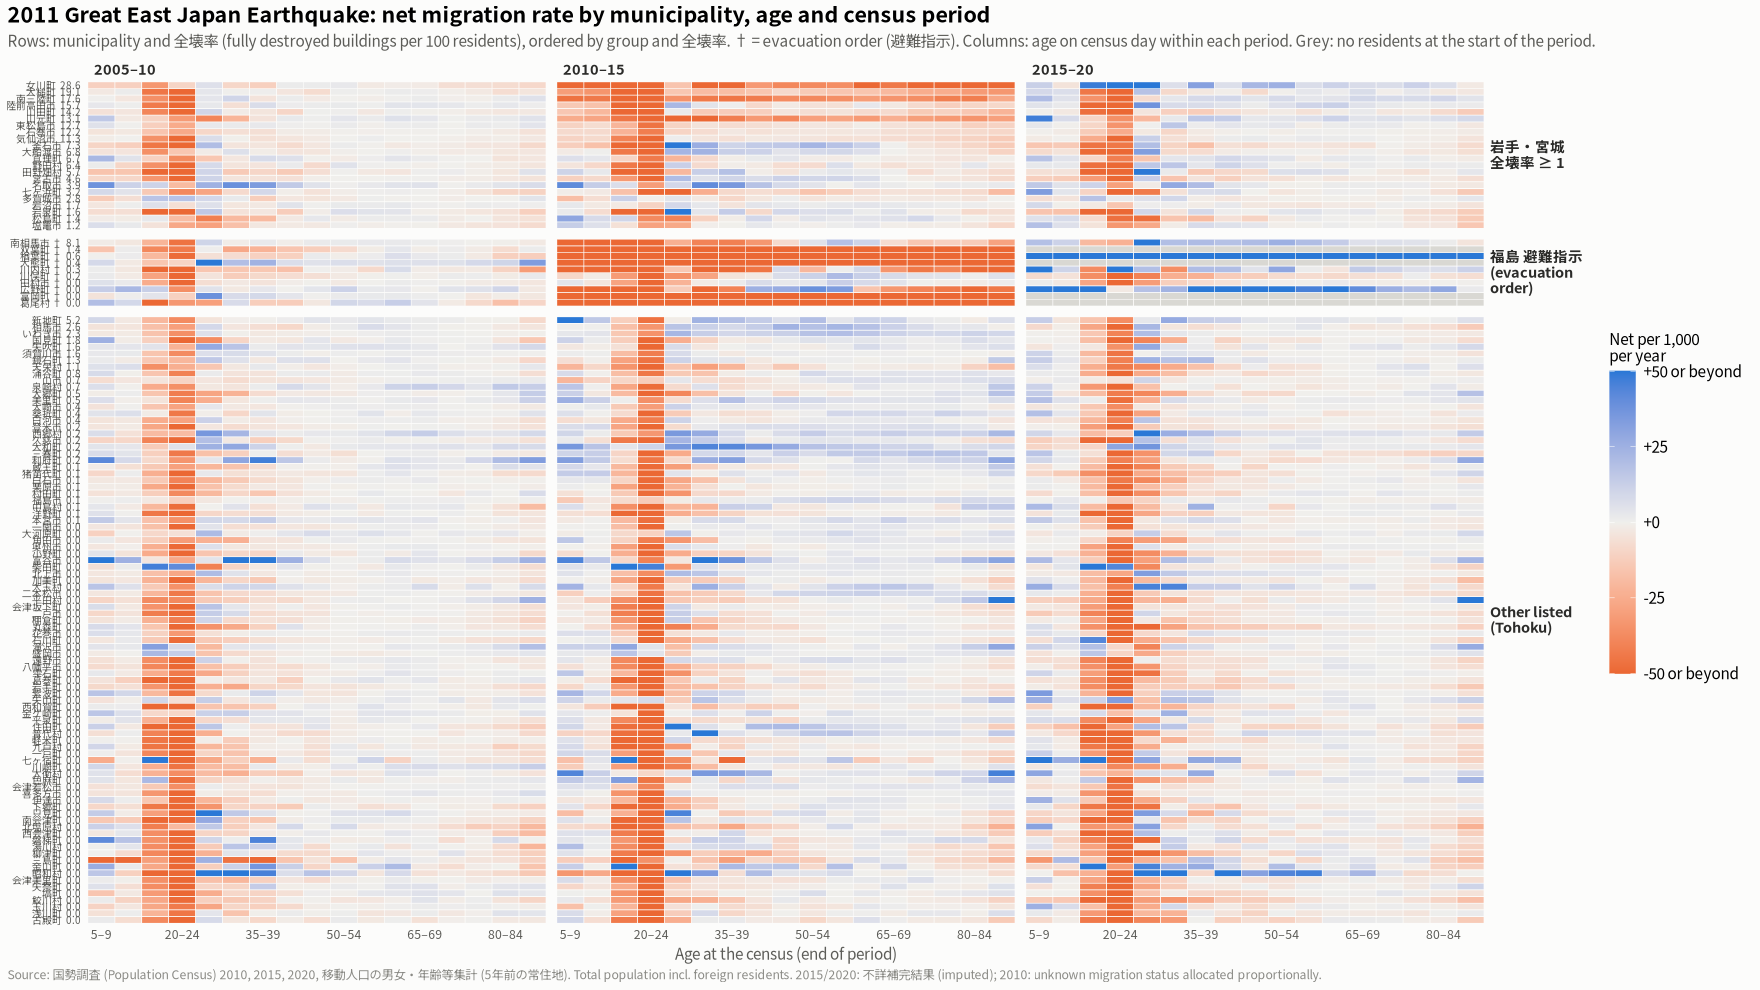

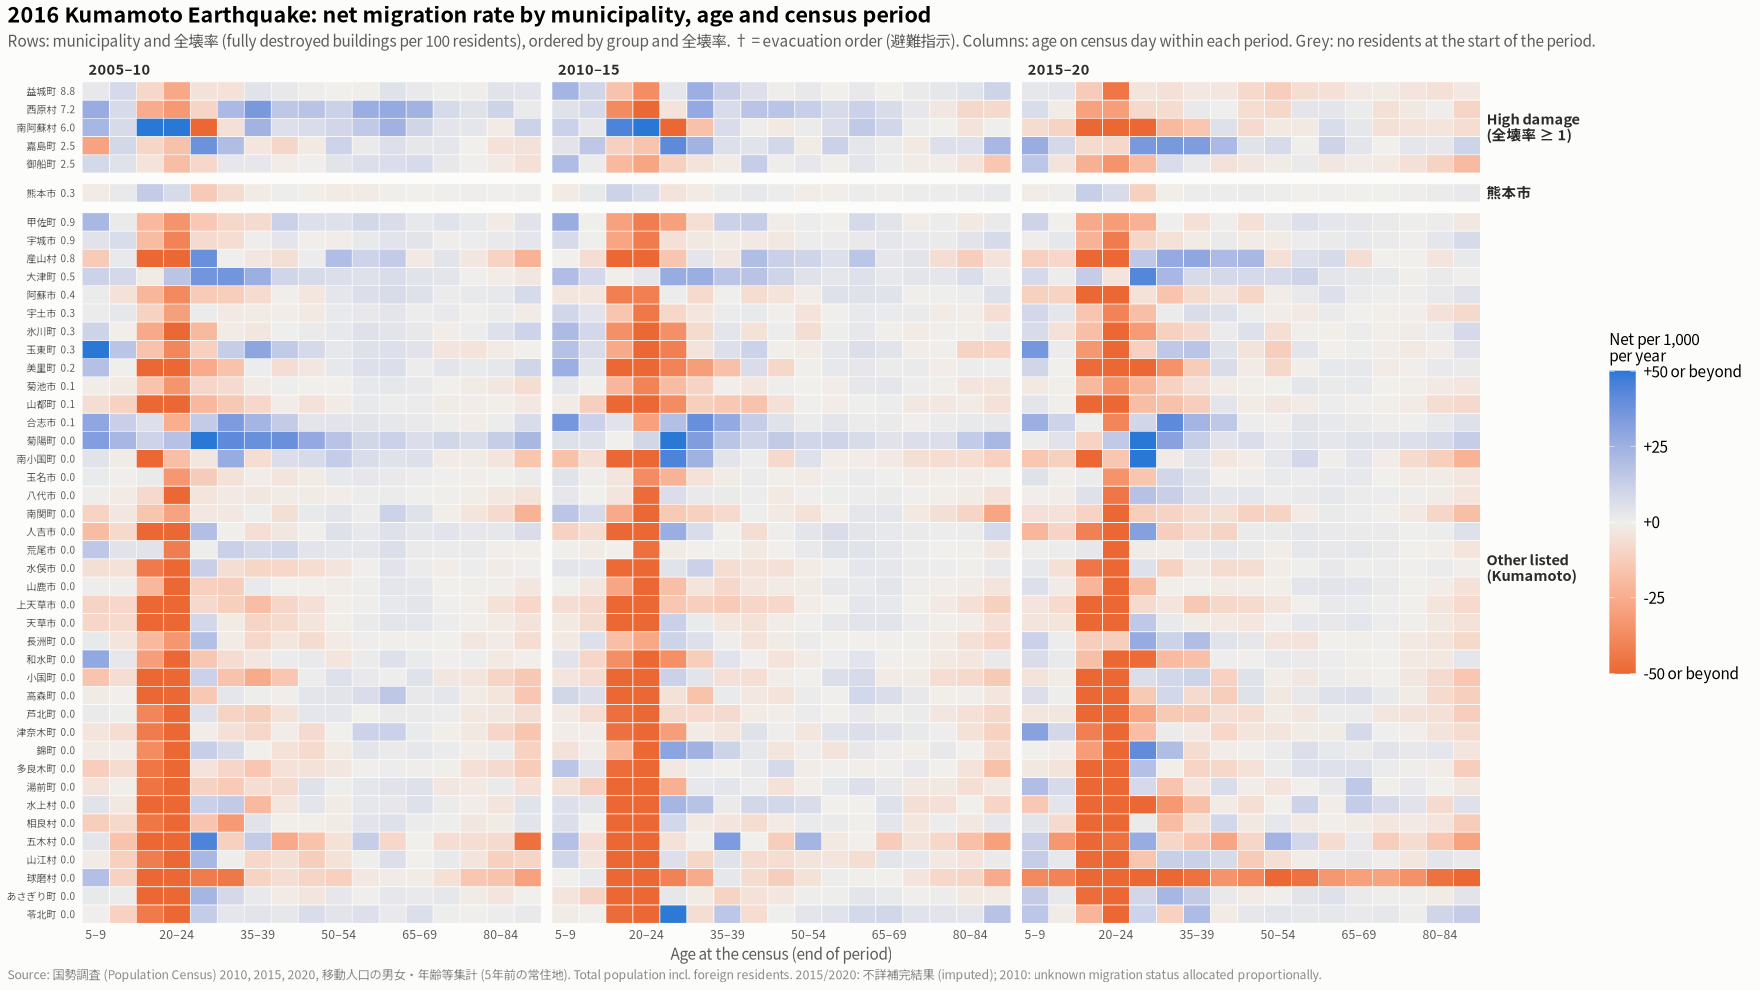

In [8]:
cap <- 50
plot_heat <- function(e) {
  ev <- events[[e]]
  st <- study |> filter(event == e) |>
    mutate(group = factor(group, levels = group_levels[[e]])) |>
    arrange(group, desc(zenkai_rate)) |>
    mutate(label = sprintf("%s%s  %s", short, ifelse(evacuation, " †", ""),
                           ifelse(is.na(zenkai_rate), "", sprintf("%.1f", zenkai_rate))))
  d <- mr |> filter(event == e) |>
    inner_join(st |> select(code, label), by = "code") |>
    mutate(label = factor(label, levels = rev(st$label)), group = factor(group, levels = group_levels[[e]]),
           rate = ifelse(p5 > 0, 1000 * net / (5 * p5), NA))
  ggplot(d, aes(age_band, label, fill = pmax(pmin(rate, cap), -cap))) +
    geom_tile(colour = surface, linewidth = 0.2) +
    facet_grid(group ~ period, scales = "free_y", space = "free_y",
               labeller = labeller(group = label_wrap_gen(14))) +
    scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                         limits = c(-cap, cap), breaks = seq(-cap, cap, 25), na.value = "#d9d8d3",
                         labels = function(v) ifelse(abs(v) == cap, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                         name = "Net per 1,000\nper year") +
    scale_x_discrete(labels = function(l) ifelse(seq_along(l) %% 3 == 1, band_lab[l], ""), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    labs(title = sprintf("%s: net migration rate by municipality, age and census period", ev$title),
         subtitle = paste0("Rows: municipality and 全壊率 (fully destroyed buildings per 100 residents), ordered by group and 全壊率. ",
                           "† = evacuation order (避難指示). Columns: age on census day within each period. ",
                           "Grey: no residents at the start of the period."),
         x = "Age at the census (end of period)", y = NULL, caption = src_note) +
    base_theme() +
    theme(panel.grid.major.y = element_blank(), legend.position = "right", legend.justification = "center",
          legend.key.height = unit(1.4, "cm"), axis.text.y = element_text(size = 6.5),
          strip.text.y = element_text(angle = 0, hjust = 0), panel.spacing = unit(0.25, "cm"))
}
show_save(plot_heat("tohoku"), "05_heatmap_tohoku", height = 19)
show_save(plot_heat("kumamoto"), "06_heatmap_kumamoto", height = 9.5)

## 5. 住民基本台帳 vs census

Figures 7–8 put the census rates next to a 住民基本台帳 (住基) estimate for the same periods, groups and age bands. The census counts people where they **live**; 住基 counts where they are **registered**.

**住基 net migration: cohort-component residual on the published 5-year bands**
- A cohort aged *x*–*x*+4 at the start count is aged *x*+5–*x*+9 five years later. So no ungrouping is needed.
- NM = P<sub>end</sub>(band + 1) − P<sub>start</sub>(band) + deaths of the cohort.
- **Cohort deaths:** half of the period's deaths in the start band plus half of those in the end band (Lexis). The top band takes half of the deaths at 75–79 plus all deaths at 80+.
- **Rate** = 1000 · NM ÷ (span · (P<sub>start</sub> − cohort deaths)), per 1,000 per year. The denominator approximates the census P<sub>5</sub>: the start population that survives the period.
- Japanese residents (`basis == "japanese"`), both sexes. Deaths from 人口動態統計 (Japanese, by residence).

**Windows** (住基 count dates differ from census days, 1 October):

| Census period | 住基 window | span | Deaths |
|---|---|---|---|
| 2005–10 | 2005-03-31 → 2010-03-31 | 5 | 0.75·D<sub>2005</sub> + D<sub>2006–09</sub> + 0.25·D<sub>2010</sub>; D<sub>2005</sub> ≈ D<sub>2006</sub> (2005 not in the data) |
| 2010–15 | 2010-03-31 → 2015-01-01 | 4.75 | 0.75·D<sub>2010</sub> + D<sub>2011–14</sub> |
| 2015–20 | 2015-01-01 → 2020-01-01 | 5 | D<sub>2015–19</sub> |

**Approximations**
- **2010–15 window is 4.75 years.** The cohort ages only 4.75 years, but it is still moved up a full band. Where neighbouring bands differ in size, this biases the rate by up to a few per 1,000. The window starts in 2010 so that it contains the quake, like the census period.
- **Top band:** 80+ at the end of the period, because the 2010 count has no finer band. The census 80–84 and 85+ are summed to match.
- **2005–10 excludes the municipalities formed or enlarged by mergers inside the window** (the 2005–06 Heisei mergers; 熊本市 in 2008 and 2010), in both sources. Their 2005-03-31 住基 count is missing or covers only part of the present municipality. The list is printed below.
- **Coverage differs.** The census includes foreign residents, and it does not see emigration abroad. 住基 here is Japanese only.
- **Victims:** both sources leave the 2011 tsunami victims out of migration. The census counts survivors only; the residual adds deaths back.


In [9]:
bands_end <- c(paste0(seq(5, 75, 5), "_", seq(9, 79, 5)), "80+")      # age at the end of the period
bands_start <- c(paste0(seq(0, 70, 5), "_", seq(4, 74, 5)), "75+")     # the same cohort at the start
top80 <- function(b) ifelse(b %in% c("80+", "80_84", "85_89", "90_94", "95_99", "100+"), "80+", b)

jp <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計", year %in% c(2005, 2010, 2015, 2020),
         age_band != "total") |>
  mutate(age_band = as.character(age_band)) |>
  group_by(code, year) |> filter(!(age_band == "80+" & any(age_band == "80_84"))) |> ungroup() |>   # per year
  mutate(band = top80(age_band)) |>
  group_by(code, year, band) |> summarise(P = sum(pop), .groups = "drop")
jd <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, sex == "計", year %in% 2006:2019, !age_band %in% c("total", "unknown")) |>
  mutate(band = top80(as.character(age_band))) |>
  group_by(code, year, band) |> summarise(D = sum(n), .groups = "drop")
Dy <- function(y) jd |> filter(year == y) |> select(code, band, D)
# Deaths over each window, by band (calendar-year deaths weighted by overlap)
win <- tibble(period = c("2005–10", "2010–15", "2015–20"), y0 = c(2005, 2010, 2015), y1 = c(2010, 2015, 2020),
              span = c(5, 4.75, 5))
wdeath <- list(
  "2005–10" = list(y = c(2006, 2006:2009, 2010), w = c(0.75, rep(1, 4), 0.25)),   # 2005 approximated by 2006
  "2010–15" = list(y = 2010:2014, w = c(0.75, rep(1, 4))),
  "2015–20" = list(y = 2015:2019, w = rep(1, 5)))
Dw <- bind_rows(lapply(names(wdeath), function(pp) {
  bind_rows(Map(function(y, w) Dy(y) |> mutate(D = w * D), wdeath[[pp]]$y, wdeath[[pp]]$w)) |>
    group_by(code, band) |> summarise(D = sum(D), .groups = "drop") |> mutate(period = pp)
}))

all_bands <- c(paste0(seq(0, 75, 5), "_", seq(4, 79, 5)), "80+")
jumin_cc <- bind_rows(lapply(seq_len(nrow(win)), function(i) {
  w <- win[i, ]
  s <- jp |> filter(year == w$y0) |> select(code, band, P0 = P)
  e <- jp |> filter(year == w$y1) |> select(code, band, P1 = P)
  d <- Dw |> filter(period == w$period) |> select(code, band, D)
  grid <- expand_grid(code = unique(s$code), k = seq_along(bands_end)) |>
    mutate(band_end = bands_end[k], band_start = bands_start[k])
  grid |>
    # start population: 75+ = 75-79 + 80+
    left_join(s |> mutate(band = ifelse(band %in% c("75_79", "80+"), "75+", band)) |>
                group_by(code, band) |> summarise(P0 = sum(P0), .groups = "drop"),
              by = c("code", "band_start" = "band")) |>
    left_join(e, by = c("code", "band_end" = "band")) |>
    # cohort deaths: half in the start band, half in the end band; the top cohort takes all deaths at 80+
    left_join(d |> rename(D_s = D), by = c("code", "band_start" = "band")) |>
    left_join(d |> rename(D_e = D), by = c("code", "band_end" = "band")) |>
    left_join(d |> filter(band == "75_79") |> select(code, D_75 = D), by = "code") |>
    mutate(D_s = ifelse(band_start == "75+", D_75, D_s),
           Dc = ifelse(band_end == "80+", 0.5 * D_s + D_e, 0.5 * coalesce(D_s, 0) + 0.5 * coalesce(D_e, 0)),
           NM = P1 - P0 + Dc, base = w$span * (P0 - Dc), period = w$period) |>
    select(code, period, band = band_end, P0, P1, Dc, NM, base)
}))
stopifnot(!anyNA(jumin_cc$NM[!(jumin_cc$period == "2005–10" & is.na(jumin_cc$P0))]))

census_cc <- mr |>
  mutate(band = ifelse(age_band %in% c("80_84", "85+"), "80+", as.character(age_band))) |>
  group_by(code, period = as.character(period), band) |>
  summarise(NM = sum(net), base = 5 * sum(p5), .groups = "drop")

# Mergers inside 2005-10 (the Heisei mergers of 2005-06, 熊本市 2008 and 2010): the
# 2005-03-31 count is missing, or covers only part of today's municipality. Flag a code
# when 2005 is missing or any year-on-year change 2005->2010 exceeds its median change
# over 2005-2012 by more than 2.5 points; flagged codes are dropped from 2005-10 in both sources.
merged0506 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計", age_band == "total", year %in% 2005:2012) |>
  arrange(code, year) |> group_by(code) |>
  mutate(g = pop / lag(pop) - 1) |>
  summarise(missing_2005 = !any(year == 2005),
            jump = any(g[year <= 2010] - median(g, na.rm = TRUE) > 0.025, na.rm = TRUE), .groups = "drop") |>
  filter(missing_2005 | jump) |> pull(code)
cat("Dropped from 2005–10 (mergers inside the window):", length(merged0506), "municipalities:",
    paste(study$short[match(merged0506, study$code)], collapse = ", "), "\n")

cmp <- bind_rows(jumin_cc |> select(code, period, band, NM, base) |> mutate(source = "住民基本台帳 (registered, residual)"),
                 census_cc |> mutate(source = "Census (where people live)")) |>
  filter(!(period == "2005–10" & code %in% merged0506)) |>
  inner_join(study |> select(code, event, group), by = "code") |>
  mutate(band = factor(band, levels = bands_end), period = factor(period, levels = periods))
src_levels <- c("Census (where people live)", "住民基本台帳 (registered, residual)")
cmp_g <- cmp |> group_by(event, group, period, source, band) |>
  summarise(rate = 1000 * sum(NM) / sum(base), .groups = "drop") |>
  mutate(source = factor(source, levels = src_levels))

# Table: ages 5+ pooled, per 1,000 per year
cmp |> group_by(event, group, period, source) |>
  summarise(rate = 1000 * sum(NM) / sum(base), .groups = "drop") |>
  mutate(source = ifelse(grepl("^Census", source), "census", "jumin")) |>
  pivot_wider(names_from = source, values_from = rate) |>
  mutate(difference = jumin - census, group = factor(group, levels = unlist(group_levels))) |>
  mutate(across(c(census, jumin, difference), ~ round(.x, 1))) |>
  arrange(event, group, period) |> as.data.frame()


Dropped from 2005–10 (mergers inside the window): 35 municipalities: 盛岡市, 宮古市, 花巻市, 久慈市, 遠野市, 一関市, 二戸市, 八幡平市, 奥州市, 西和賀町, 洋野町, 石巻市, 気仙沼市, 登米市, 栗原市, 東松島市, 大崎市, 美里町, 南三陸町, 会津若松市, 白河市, 須賀川市, 喜多方市, 二本松市, 南相馬市, 伊達市, 南会津町, 会津美里町, 熊本市, 八代市, 玉名市, 天草市, 合志市, 和水町, 氷川町 


event,group,period,census,jumin,difference
<chr>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
kumamoto,High damage (全壊率 ≥ 1),2005–10,2.4,2.0,-0.4
kumamoto,High damage (全壊率 ≥ 1),2010–15,2.6,2.4,-0.2
kumamoto,High damage (全壊率 ≥ 1),2015–20,-5.0,-6.7,-1.6
kumamoto,熊本市,2010–15,1.3,0.6,-0.8
kumamoto,熊本市,2015–20,0.9,-0.4,-1.3
kumamoto,Other listed (Kumamoto),2005–10,-2.3,-2.2,0.1
kumamoto,Other listed (Kumamoto),2010–15,-2.9,-2.7,0.2
kumamoto,Other listed (Kumamoto),2015–20,-2.3,-3.9,-1.7
tohoku,岩手・宮城 全壊率 ≥ 1,2005–10,-1.7,-2.7,-1.0


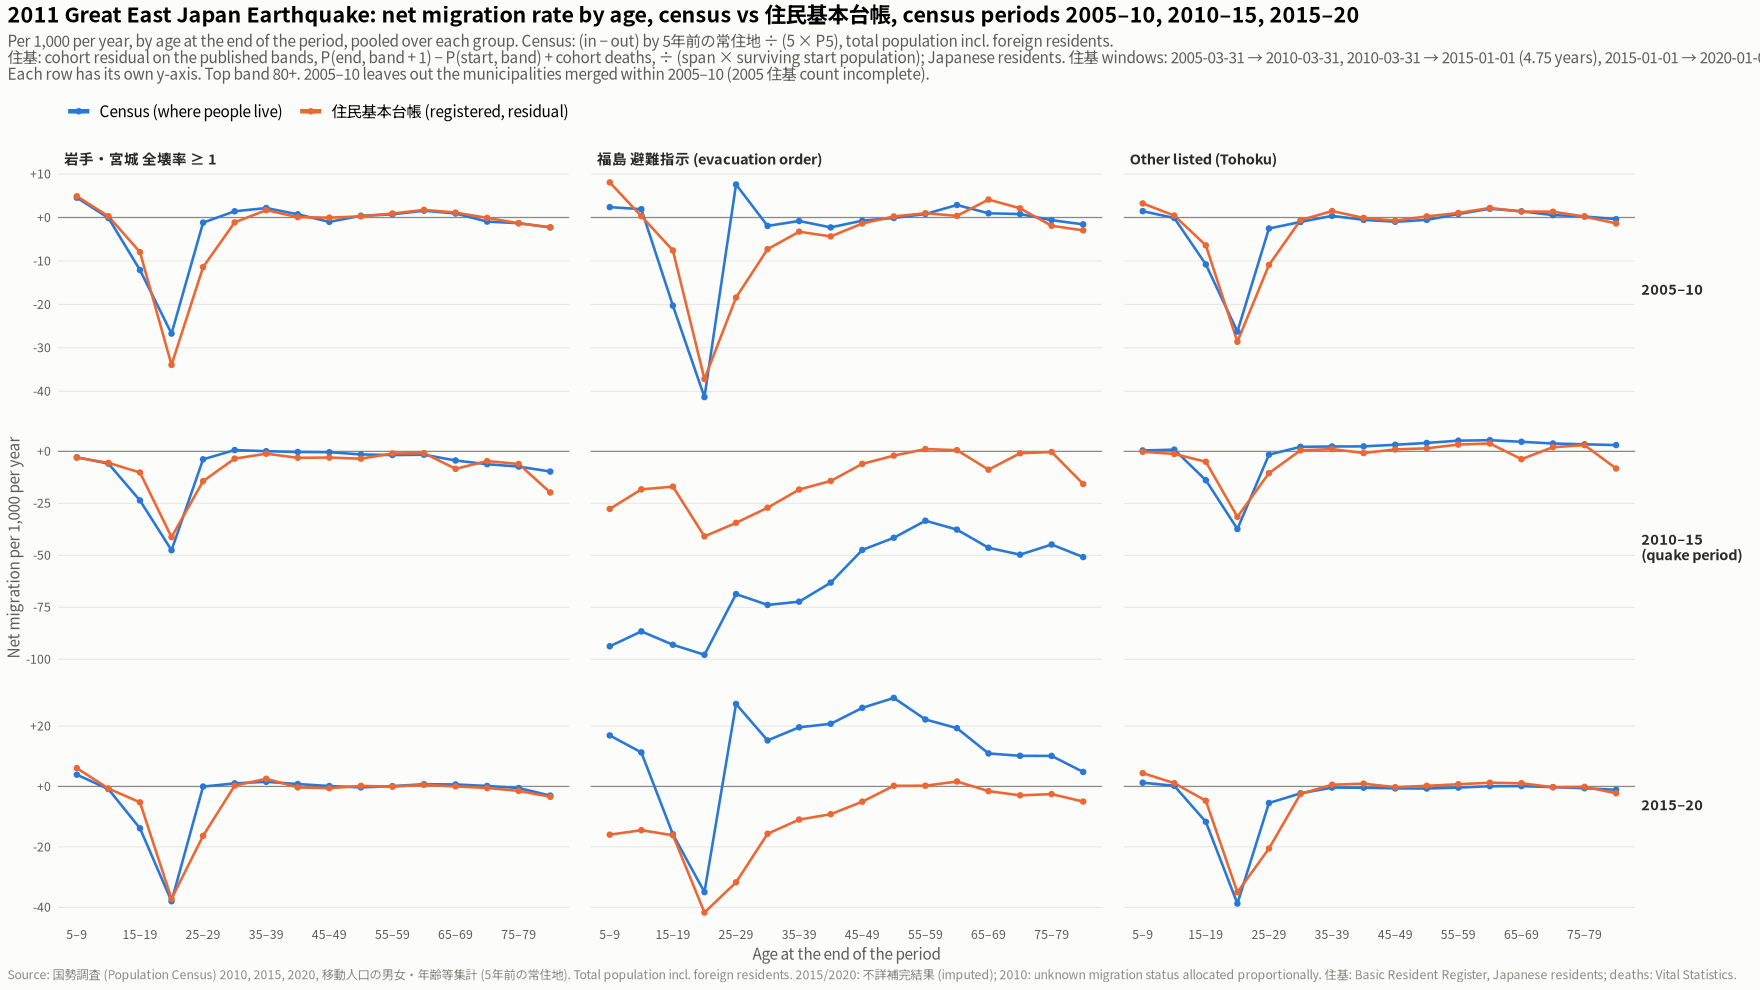

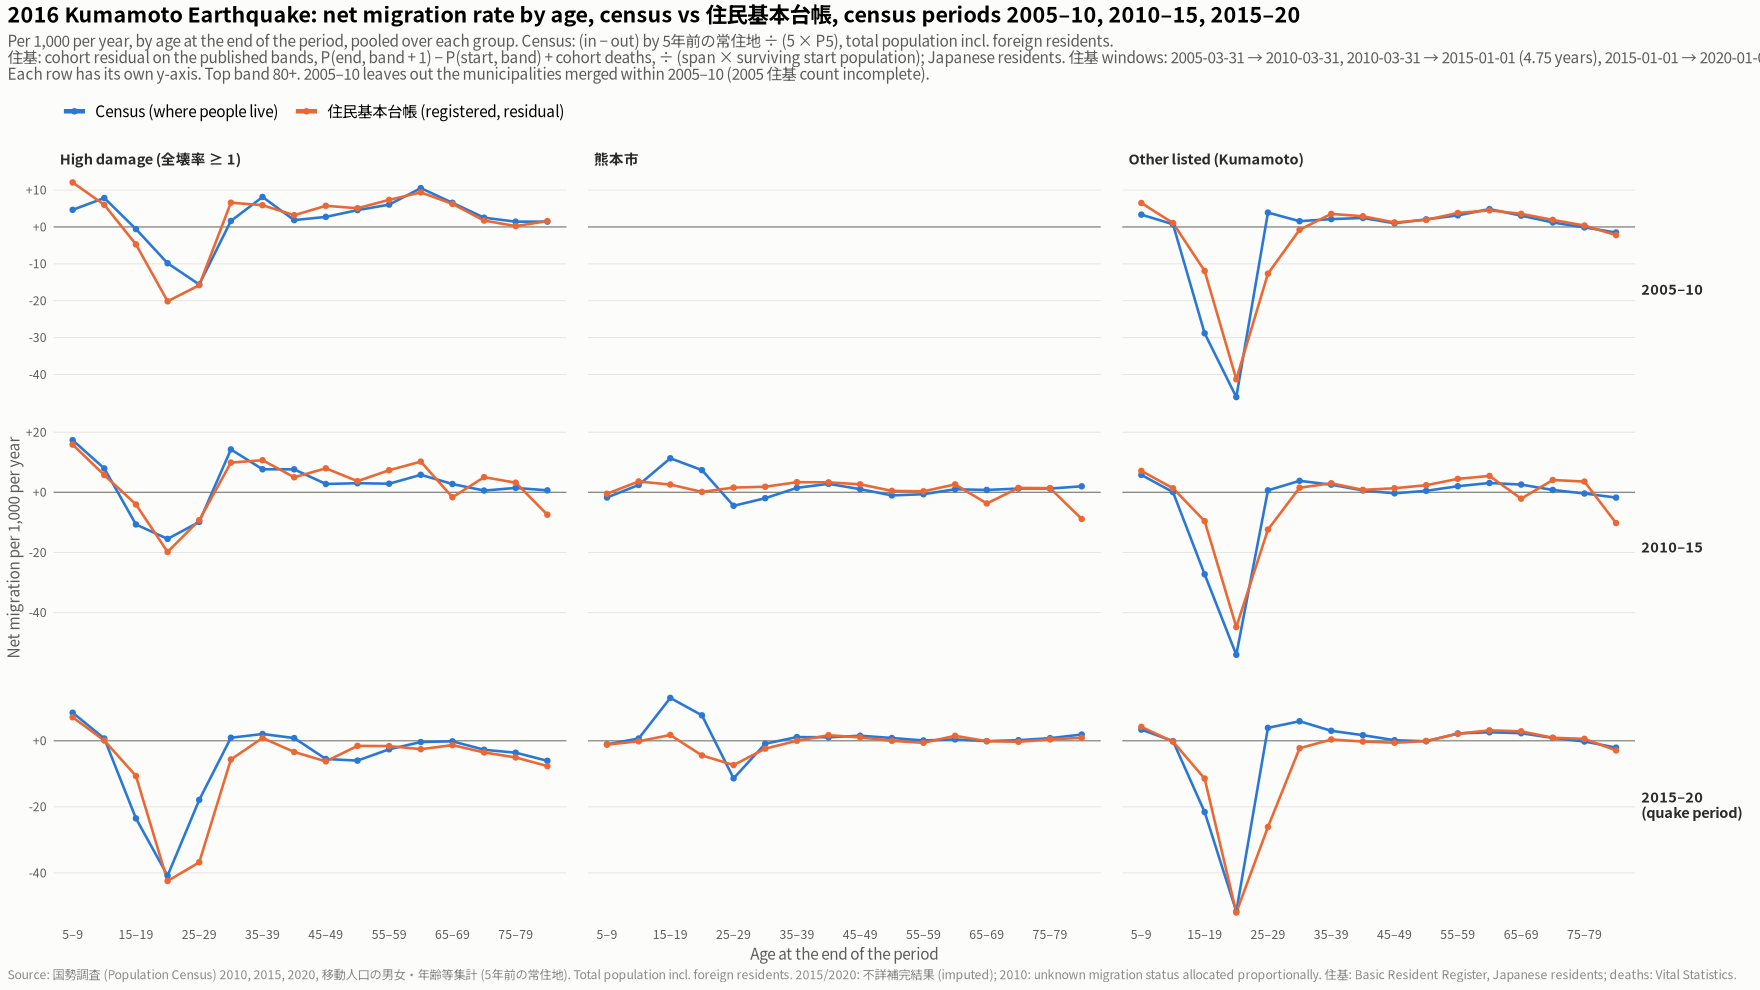

In [10]:
plot_jumin_census <- function(e) {
  ev <- events[[e]]
  d <- cmp_g |> filter(event == e) |> mutate(group = factor(group, levels = group_levels[[e]]))
  ggplot(d, aes(band, rate, colour = source, group = source)) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(linewidth = 0.8) + geom_point(size = 1.4) +
    facet_grid(period ~ group, scales = "free_y",
               labeller = labeller(period = function(p) ifelse(p %in% ev$quake, paste0(p, "\n(quake period)"), p))) +
    scale_colour_manual(values = setNames(c("#2a78d6", "#eb6834"), src_levels), name = NULL) +
    scale_x_discrete(labels = function(l) ifelse(seq_along(l) %% 2 == 1, sub("_", "–", l), "")) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = sprintf("%s: net migration rate by age, census vs 住民基本台帳, census periods 2005–10, 2010–15, 2015–20", ev$title),
         subtitle = paste0("Per 1,000 per year, by age at the end of the period, pooled over each group. ",
                           "Census: (in − out) by 5年前の常住地 ÷ (5 × P5), total population incl. foreign residents.\n",
                           "住基: cohort residual on the published bands, P(end, band + 1) − P(start, band) + cohort deaths, ÷ (span × surviving start population); Japanese residents. ",
                           "住基 windows: 2005-03-31 → 2010-03-31, 2010-03-31 → 2015-01-01 (4.75 years), 2015-01-01 → 2020-01-01.\n",
                           "Each row has its own y-axis. Top band 80+. 2005–10 leaves out the municipalities merged within 2005–10 (2005 住基 count incomplete)."),
         x = "Age at the end of the period", y = "Net migration per 1,000 per year",
         caption = paste0(src_note, " 住基: Basic Resident Register, Japanese residents; deaths: Vital Statistics.")) +
    base_theme() +
    theme(strip.text.y = element_text(angle = 0, hjust = 0)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}
show_save(plot_jumin_census("tohoku"), "07_jumin_vs_census_tohoku", width = 17, height = 10)
show_save(plot_jumin_census("kumamoto"), "08_jumin_vs_census_kumamoto", width = 17, height = 10)


## Notes

- **Residence, not registration.** The census counts people where they usually live on census day. Evacuees who kept their 住民票 count as out-migrants here but not in 住民基本台帳 (3r–7r). The two sources therefore differ most in the Fukushima evacuation zones.
- **Survivors only.** People who died during the period appear in neither P<sub>5</sub> nor the flows, so the tsunami deaths do not enter the rates.
- **Emigration abroad** is not observed; immigration is counted as in-migration. Foreign residents (e.g. technical trainees in fishery processing) are included in all counts.
- **Moves within the period are not seen.** Only the address five years earlier is asked, so someone who left and came back counts as a stayer, and a temporary move to 仮設 housing in a neighbouring municipality that ended before the census is invisible.
- **Mergers:** 藤沢町 (2011) is summed into 一関市, and 富谷町/滝沢村/熊本市 code changes are applied (`src/merge_map.csv`). For the 2010 census, moves between 藤沢町 and 一関市 count as both in- and out-migration of the merged unit; net migration is unaffected.
- **2010 rates at ages 15–24** are biased upwards by the unknown-status correction (section 1).
- **Other disasters inside a period.** The Kumamoto 2015–20 period ends three months after the July 2020 heavy rain (令和2年7月豪雨), which flooded the 球磨川 basin. 球磨村's loss at every age in 2015–20 (figure 6), and part of 人吉市's and 芦北町's, is mostly that flood, not the earthquake. The period also contains the first COVID-19 months (spring–autumn 2020).